In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

ROOT         = Path(r"D:\hocki7\Data Annalyst\Detai")
PATH_CLEANED = ROOT / "1_data" / "processed" / "03_cleaned.csv"
FIG_DIR      = ROOT / "5_reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Style biểu đồ
plt.rcParams['figure.figsize']  = (12, 5)
plt.rcParams['font.size']       = 11
plt.rcParams['axes.spines.top']    = False
plt.rcParams['axes.spines.right']  = False
sns.set_palette("husl")

df = pd.read_csv(PATH_CLEANED)

print(f"✅ Load xong: {df.shape[0]:,} dòng | {df.shape[1]} cột")
print(f"\nDanh sách cột:")
for i, col in enumerate(df.columns, 1):
    print(f"  {i:2}. {col:<25} {str(df[col].dtype):<10} "
          f"min={df[col].min():.1f} max={df[col].max():.1f}")

✅ Load xong: 200,000 dòng | 25 cột

Danh sách cột:
   1. isFraud                   int64      min=0.0 max=1.0
   2. TransactionAmt_log        float64    min=0.2 max=10.4
   3. ProductCD_enc             int64      min=0.0 max=4.0
   4. card1                     int64      min=1004.0 max=18395.0
   5. card4_enc                 int64      min=0.0 max=4.0
   6. card6_enc                 int64      min=0.0 max=4.0
   7. addr1                     float64    min=100.0 max=540.0
   8. addr2                     float64    min=10.0 max=102.0
   9. dist1                     float64    min=0.0 max=10286.0
  10. dist2                     float64    min=0.0 max=9337.0
  11. P_emaildomain_enc         int64      min=0.0 max=9.0
  12. R_emaildomain_enc         int64      min=0.0 max=9.0
  13. C1                        float64    min=0.0 max=4685.0
  14. C2                        float64    min=0.0 max=5691.0
  15. C6                        float64    min=0.0 max=2253.0
  16. C_total                   f

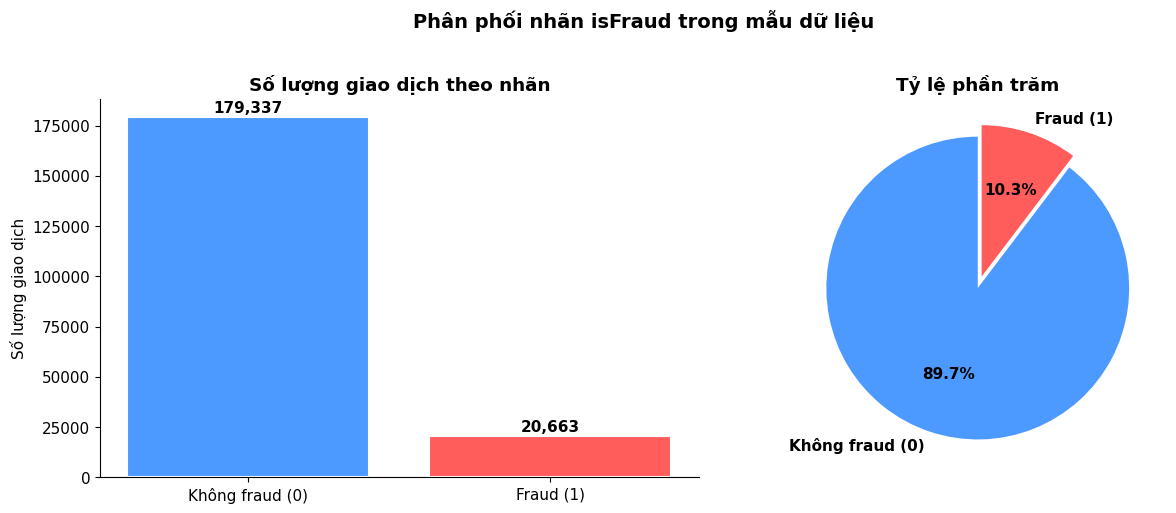

📊 Nhận xét:
   Không fraud : 179,337 giao dịch (89.7%)
   Fraud       : 20,663 giao dịch (10.3%)
   Tỷ lệ       : 8.7 : 1

   → Đây là mẫu ĐÃ CÂN CHỈNH (stratified sampling), tỷ lệ thực tế
     trong toàn bộ dataset gốc chỉ khoảng 0.13-3.5% fraud.
   → Khi đánh giá mô hình ở Giai đoạn 4, KHÔNG dùng accuracy
     làm thước đo chính vì lớp vẫn mất cân bằng đáng kể.


In [ ]:
#Biểu đồ 1 :Phân phối nhãn fraud/không fraud. 
#Đây là biểu đồ quan trọng nhất vì nó xác nhận lại vấn đề mất cân bằng lớp mà toàn bộ dự án phải xử lý.

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Biểu đồ trái: Bar chart số lượng
vc = df['isFraud'].value_counts().sort_index()
colors = ['#4C9AFF', '#FF5C5C']
labels = ['Không fraud (0)', 'Fraud (1)']

bars = axes[0].bar(labels, vc.values, color=colors, edgecolor='white', linewidth=1.5)
axes[0].set_title('Số lượng giao dịch theo nhãn', fontweight='bold')
axes[0].set_ylabel('Số lượng giao dịch')

# Ghi số liệu lên đầu cột
for bar, val in zip(bars, vc.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2000,
                 f'{val:,}', ha='center', fontweight='bold', fontsize=11)

# Biểu đồ phải: Pie chart tỷ lệ %
pct = df['isFraud'].value_counts(normalize=True).sort_index() * 100
axes[1].pie(pct.values, labels=labels, colors=colors, autopct='%1.1f%%',
            startangle=90, explode=(0, 0.08),
            textprops={'fontsize': 11, 'fontweight': 'bold'})
axes[1].set_title('Tỷ lệ phần trăm', fontweight='bold')

plt.suptitle('Phân phối nhãn isFraud trong mẫu dữ liệu', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(str(FIG_DIR / "01_fraud_distribution.png"), dpi=150, bbox_inches='tight')
plt.show()

print(f"📊 Nhận xét:")
print(f"   Không fraud : {vc[0]:,} giao dịch ({pct[0]:.1f}%)")
print(f"   Fraud       : {vc[1]:,} giao dịch ({pct[1]:.1f}%)")
print(f"   Tỷ lệ       : {vc[0]/vc[1]:.1f} : 1")
print(f"\n   → Đây là mẫu ĐÃ CÂN CHỈNH (stratified sampling), tỷ lệ thực tế")
print(f"     trong toàn bộ dataset gốc chỉ khoảng 0.13-3.5% fraud.")
print(f"   → Khi đánh giá mô hình ở Giai đoạn 4, KHÔNG dùng accuracy")
print(f"     làm thước đo chính vì lớp vẫn mất cân bằng đáng kể.")






C:\Users\luuxu\AppData\Local\Temp\ipykernel_17524\1539009254.py:20: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[1].boxplot(data_to_plot, labels=['Không fraud', 'Fraud'],


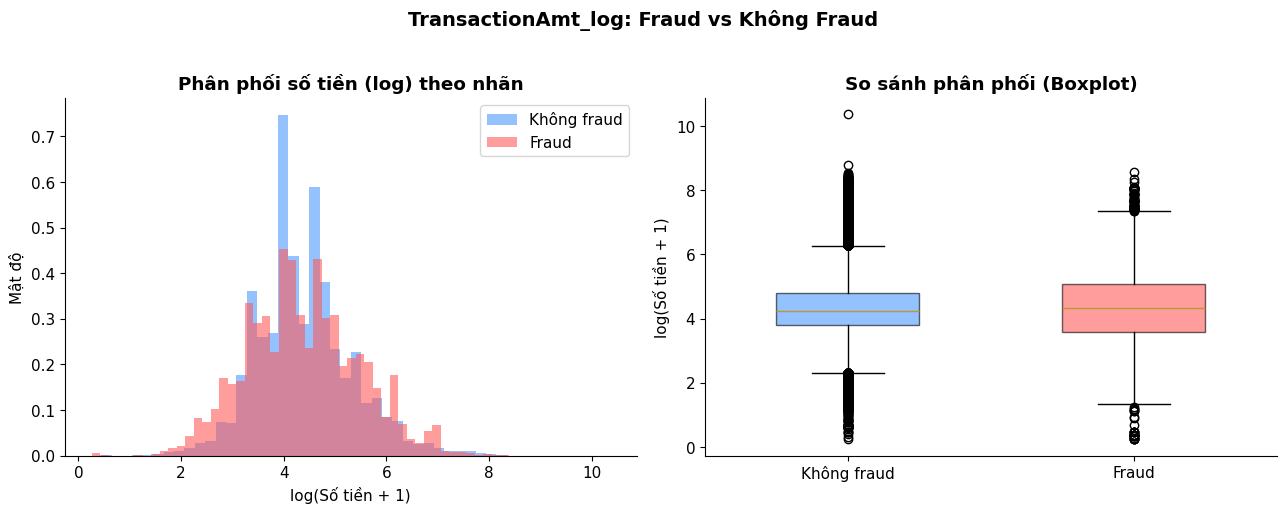

📊 Thống kê TransactionAmt_log theo nhãn:
            count  mean   std   min   25%   50%   75%    max
isFraud                                                     
0        179337.0  4.38  0.93  0.24  3.81  4.24  4.80  10.37
1         20663.0  4.37  1.10  0.26  3.58  4.33  5.09   8.55

   → Trung bình fraud    : 4.37
   → Trung bình không fraud: 4.38
   → Chênh lệch: Fraud thấp hơn


In [ ]:
#Biểu đồ 2: Phân phối số tiền giao dịch (TransactionAmt_log)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Trái: Histogram so sánh fraud vs không fraud
axes[0].hist(df[df['isFraud']==0]['TransactionAmt_log'], bins=50,
             alpha=0.6, label='Không fraud', color='#4C9AFF', density=True)
axes[0].hist(df[df['isFraud']==1]['TransactionAmt_log'], bins=50,
             alpha=0.6, label='Fraud', color='#FF5C5C', density=True)
axes[0].set_title('Phân phối số tiền (log) theo nhãn', fontweight='bold')
axes[0].set_xlabel('log(Số tiền + 1)')
axes[0].set_ylabel('Mật độ')
axes[0].legend()

# Phải: Boxplot so sánh
data_to_plot = [
    df[df['isFraud']==0]['TransactionAmt_log'],
    df[df['isFraud']==1]['TransactionAmt_log']
]
bp = axes[1].boxplot(data_to_plot, labels=['Không fraud', 'Fraud'],
                       patch_artist=True, widths=0.5)
for patch, color in zip(bp['boxes'], ['#4C9AFF', '#FF5C5C']):
    patch.set_facecolor(color)
    patch.set_alpha(0.6)
axes[1].set_title('So sánh phân phối (Boxplot)', fontweight='bold')
axes[1].set_ylabel('log(Số tiền + 1)')

plt.suptitle('TransactionAmt_log: Fraud vs Không Fraud', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(str(FIG_DIR / "02_amount_distribution.png"), dpi=150, bbox_inches='tight')
plt.show()

# Thống kê số liệu
print("📊 Thống kê TransactionAmt_log theo nhãn:")
print(df.groupby('isFraud')['TransactionAmt_log'].describe().round(2).to_string())

mean_fraud    = df[df['isFraud']==1]['TransactionAmt_log'].mean()
mean_notfraud = df[df['isFraud']==0]['TransactionAmt_log'].mean()
print(f"\n   → Trung bình fraud    : {mean_fraud:.2f}")
print(f"   → Trung bình không fraud: {mean_notfraud:.2f}")
print(f"   → Chênh lệch: {'Fraud cao hơn' if mean_fraud > mean_notfraud else 'Fraud thấp hơn'}")


#ố tiền giao dịch gần như không khác biệt giữa fraud và không fraud (4.37 vs 4.38, 
# độ lệch chuẩn fraud nhỉnh hơn chút). 
# Điều này cho thấy TransactionAmt một mình không đủ sức phân biệt fraud 
# cần kết hợp với các đặc trưng khác (thời gian, hành vi C1/C2/C6...)



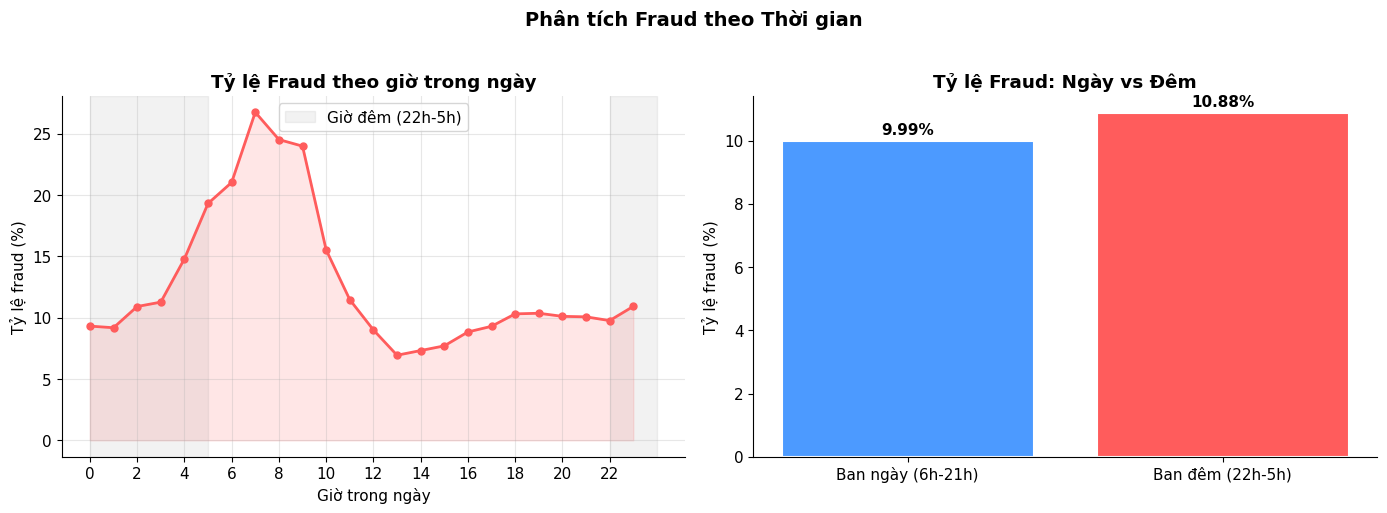

📊 Tỷ lệ fraud theo giờ (5 giờ cao nhất):
             fraud_pct  count
hour_of_day                  
7            26.771117   1468
8            24.541752    982
9            24.004306    929
6            21.045516   2219
5            19.325588   3529

📊 So sánh ngày/đêm:
   Ban ngày : 9.99%
   Ban đêm  : 10.88%
   → Chênh lệch: +0.89 điểm phần trăm


In [ ]:

# Biểu đồ 3: Tỷ lệ fraud theo giờ trong ngày

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Trái: Tỷ lệ fraud theo giờ (line chart)
fraud_by_hour = df.groupby('hour_of_day')['isFraud'].agg(['mean', 'count'])
fraud_by_hour['fraud_pct'] = fraud_by_hour['mean'] * 100

axes[0].plot(fraud_by_hour.index, fraud_by_hour['fraud_pct'],
             marker='o', linewidth=2, color='#FF5C5C', markersize=5)
axes[0].fill_between(fraud_by_hour.index, fraud_by_hour['fraud_pct'],
                       alpha=0.15, color='#FF5C5C')
axes[0].axvspan(22, 24, alpha=0.1, color='gray')
axes[0].axvspan(0, 5, alpha=0.1, color='gray', label='Giờ đêm (22h-5h)')
axes[0].set_title('Tỷ lệ Fraud theo giờ trong ngày', fontweight='bold')
axes[0].set_xlabel('Giờ trong ngày')
axes[0].set_ylabel('Tỷ lệ fraud (%)')
axes[0].set_xticks(range(0, 24, 2))
axes[0].legend()
axes[0].grid(alpha=0.3)

# Phải: So sánh is_night (bar chart)
night_fraud = df.groupby('is_night')['isFraud'].mean() * 100
bars = axes[1].bar(['Ban ngày (6h-21h)', 'Ban đêm (22h-5h)'],
                     night_fraud.values,
                     color=['#4C9AFF', '#FF5C5C'], edgecolor='white', linewidth=1.5)
axes[1].set_title('Tỷ lệ Fraud: Ngày vs Đêm', fontweight='bold')
axes[1].set_ylabel('Tỷ lệ fraud (%)')
for bar, val in zip(bars, night_fraud.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2,
                 f'{val:.2f}%', ha='center', fontweight='bold', fontsize=11)

plt.suptitle('Phân tích Fraud theo Thời gian', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(str(FIG_DIR / "03_fraud_by_time.png"), dpi=150, bbox_inches='tight')
plt.show()

# Thống kê
print("📊 Tỷ lệ fraud theo giờ (5 giờ cao nhất):")
print(fraud_by_hour.sort_values('fraud_pct', ascending=False)[['fraud_pct','count']].head().to_string())

print(f"\n📊 So sánh ngày/đêm:")
print(f"   Ban ngày : {night_fraud[0]:.2f}%")
print(f"   Ban đêm  : {night_fraud[1]:.2f}%")
diff = night_fraud[1] - night_fraud[0]
print(f"   → Chênh lệch: {diff:+.2f} điểm phần trăm")

#fraud tập trung mạnh vào khung giờ 5h-9h sáng (~20-27%), 
# cao hơn hẳn mức trung bình 10.3% — ngược với giả định ban đầu là ban đêm. 
# Giả thuyết is_night (22h-5h) không bắt được pattern thật; 
# cần sửa lại thành đặc trưng "giờ sáng sớm" (5h-9h) sẽ có giá trị dự đoán tốt hơn.



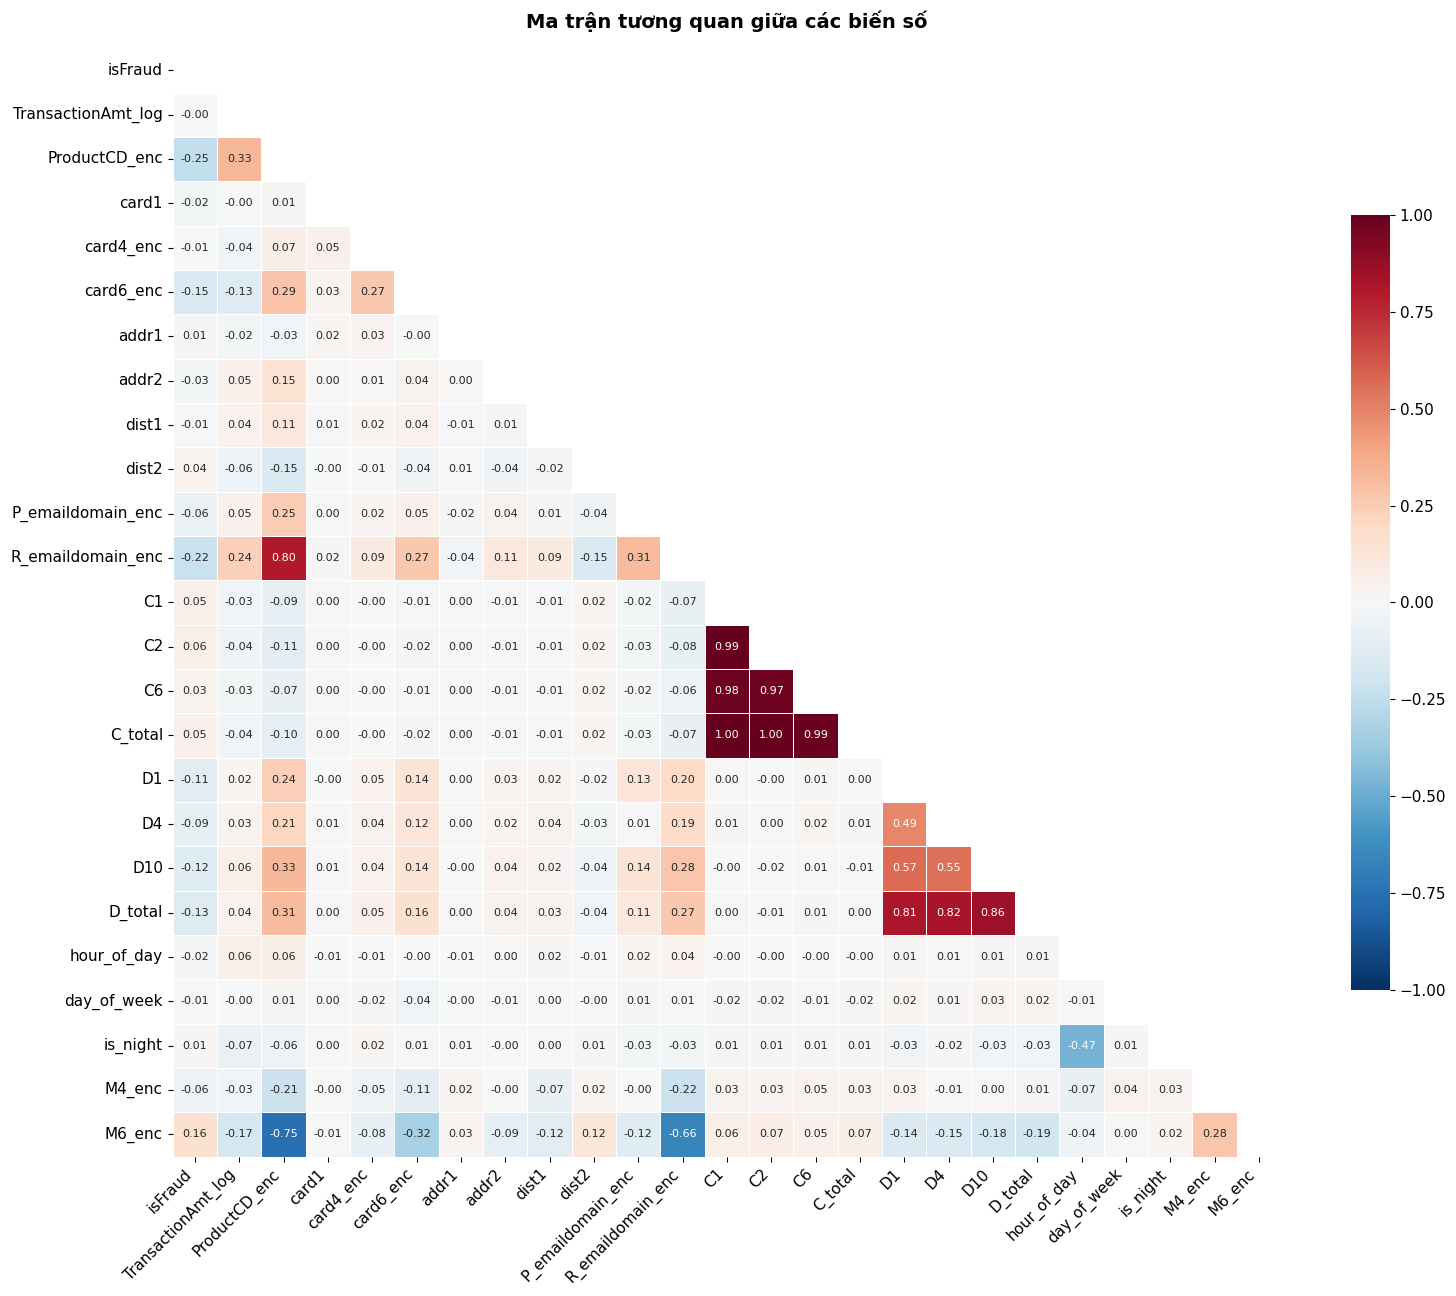

📊 Top 10 biến tương quan MẠNH NHẤT với isFraud (trị tuyệt đối):
   1. ProductCD_enc             : -0.246  (ngược chiều (-))
   2. R_emaildomain_enc         : -0.220  (ngược chiều (-))
   3. M6_enc                    : +0.159  (cùng chiều (+))
   4. card6_enc                 : -0.153  (ngược chiều (-))
   5. D_total                   : -0.130  (ngược chiều (-))
   6. D10                       : -0.119  (ngược chiều (-))
   7. D1                        : -0.112  (ngược chiều (-))
   8. D4                        : -0.092  (ngược chiều (-))
   9. P_emaildomain_enc         : -0.064  (ngược chiều (-))
  10. C2                        : +0.057  (cùng chiều (+))

📊 Cặp biến tương quan RẤT CAO với nhau (|r| > 0.8, ngoại trừ isFraud):
  ProductCD_enc ↔ R_emaildomain_enc : r=0.801  → cân nhắc bỏ bớt 1 trong 2 khi train model
  C1 ↔ C2 : r=0.994  → cân nhắc bỏ bớt 1 trong 2 khi train model
  C1 ↔ C6 : r=0.982  → cân nhắc bỏ bớt 1 trong 2 khi train model
  C1 ↔ C_total : r=0.998  → cân nhắc bỏ bớt 1

In [5]:
#Biểu đồ 4: Correlation Heatmap

# Chọn các cột số để tính tương quan (bỏ isFraud ra tính riêng để dễ đọc)
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

corr_matrix = df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(16, 13))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))  # ẩn nửa trên tam giác (đối xứng)

sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f',
            cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.7},
            annot_kws={"size": 8})
ax.set_title('Ma trận tương quan giữa các biến số', fontsize=14, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(str(FIG_DIR / "04_correlation_heatmap.png"), dpi=150, bbox_inches='tight')
plt.show()

# Top biến tương quan mạnh nhất với isFraud
print("📊 Top 10 biến tương quan MẠNH NHẤT với isFraud (trị tuyệt đối):")
fraud_corr = corr_matrix['isFraud'].drop('isFraud').abs().sort_values(ascending=False)
top10 = fraud_corr.head(10)

for i, (col, val) in enumerate(top10.items(), 1):
    direction = "cùng chiều (+)" if corr_matrix['isFraud'][col] > 0 else "ngược chiều (-)"
    print(f"  {i:2}. {col:<25} : {corr_matrix['isFraud'][col]:+.3f}  ({direction})")

# Cảnh báo đa cộng tuyến (multicollinearity) — 2 biến tương quan quá cao với nhau
print(f"\n📊 Cặp biến tương quan RẤT CAO với nhau (|r| > 0.8, ngoại trừ isFraud):")
high_corr_pairs = []
for i in range(len(numeric_cols)):
    for j in range(i+1, len(numeric_cols)):
        c1, c2 = numeric_cols[i], numeric_cols[j]
        if c1 == 'isFraud' or c2 == 'isFraud':
            continue
        r = corr_matrix.loc[c1, c2]
        if abs(r) > 0.8:
            high_corr_pairs.append((c1, c2, r))

if high_corr_pairs:
    for c1, c2, r in high_corr_pairs:
        print(f"  {c1} ↔ {c2} : r={r:.3f}  → cân nhắc bỏ bớt 1 trong 2 khi train model")
else:
    print("  Không có cặp nào — dữ liệu ổn, không bị đa cộng tuyến nghiêm trọng")

C:\Users\luuxu\AppData\Local\Temp\ipykernel_17524\2064854462.py:23: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[i].boxplot([data_notfraud, data_fraud],
C:\Users\luuxu\AppData\Local\Temp\ipykernel_17524\2064854462.py:23: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[i].boxplot([data_notfraud, data_fraud],


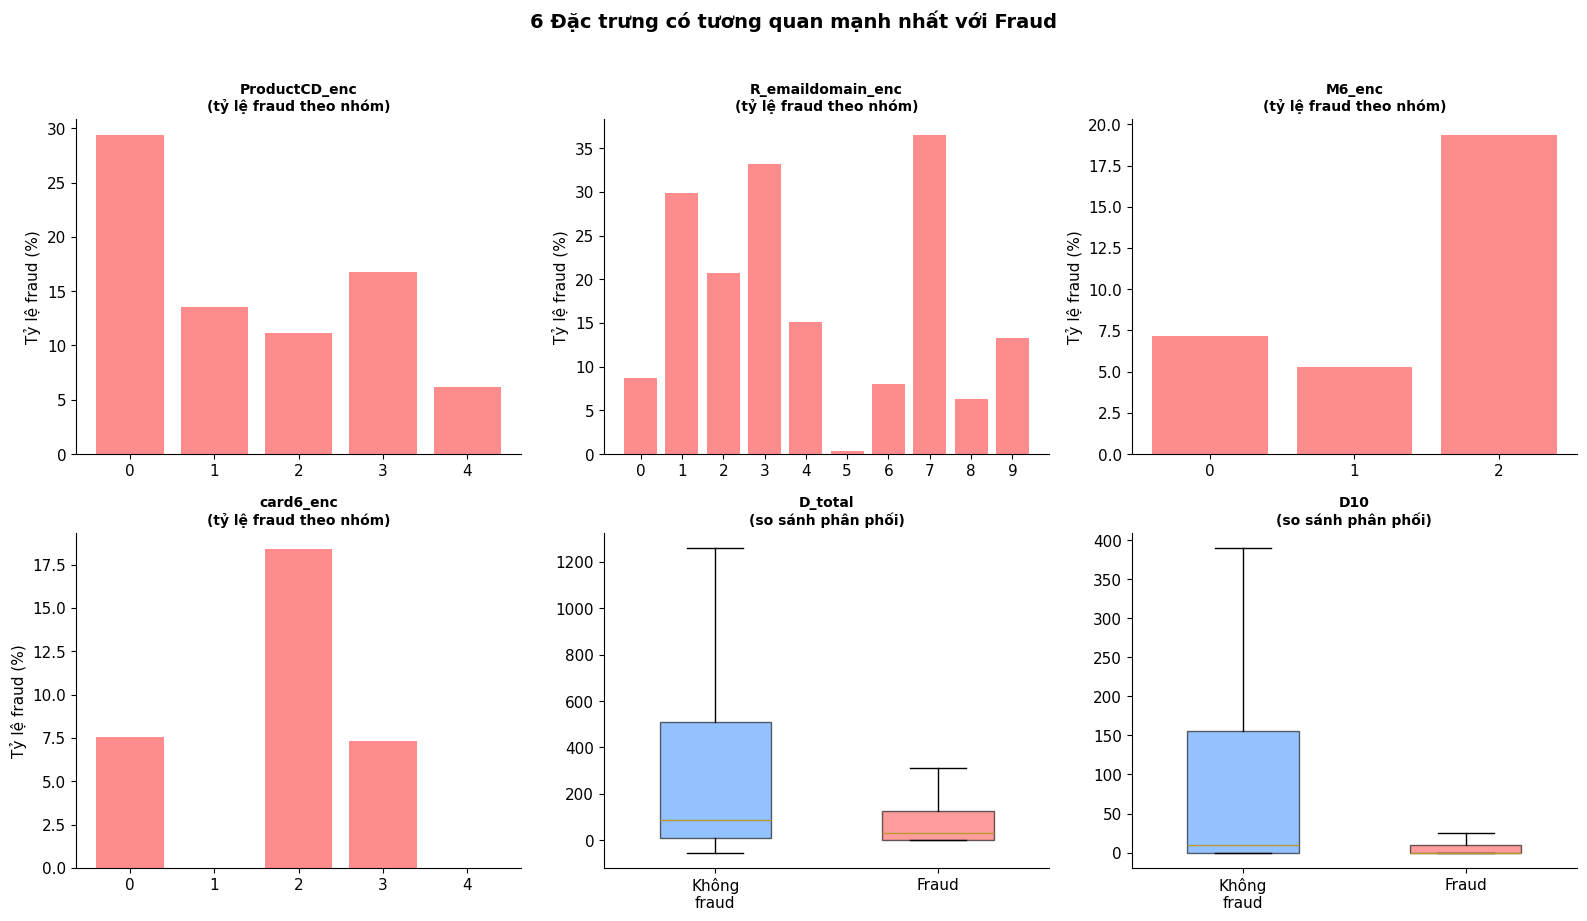

✅ Đã lưu biểu đồ vào 5_reports/figures/05_top_features_comparison.png

📋 TỔNG KẾT EDA — INSIGHT CHÍNH:
  1. Lớp mất cân bằng: 89.7% không fraud vs 10.3% fraud
  2. TransactionAmt KHÔNG phân biệt tốt fraud/không fraud
  3. Fraud tập trung cao ở khung giờ 5h-9h sáng (~20-27%)
  4. ProductCD, R_emaildomain, M6, card6 là các đặc trưng dự đoán mạnh nhất
  5. Cần loại bỏ đa cộng tuyến: bỏ C1/C2/C6 (giữ C_total), bỏ D1/D4 (giữ D10+D_total)


In [6]:
#Biểu đồ 5: So sánh Fraud vs Không Fraud theo các đặc trưng quan trọng nhất


# Lấy 6 đặc trưng tương quan mạnh nhất (từ kết quả Cell 5) để trực quan hóa sâu hơn
top_features = ['ProductCD_enc', 'R_emaildomain_enc', 'M6_enc',
                 'card6_enc', 'D_total', 'D10']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, feat in enumerate(top_features):
    data_notfraud = df[df['isFraud']==0][feat]
    data_fraud    = df[df['isFraud']==1][feat]

    # Nếu là biến rời rạc ít giá trị (encoded categorical) → dùng bar chart tỷ lệ
    if df[feat].nunique() <= 10:
        rate = df.groupby(feat)['isFraud'].mean() * 100
        axes[i].bar(rate.index.astype(str), rate.values, color='#FF5C5C', alpha=0.7)
        axes[i].set_ylabel('Tỷ lệ fraud (%)')
        axes[i].set_title(f'{feat}\n(tỷ lệ fraud theo nhóm)', fontsize=10, fontweight='bold')
    else:
        # Biến liên tục → dùng boxplot
        bp = axes[i].boxplot([data_notfraud, data_fraud],
                               labels=['Không\nfraud', 'Fraud'],
                               patch_artist=True, widths=0.5, showfliers=False)
        for patch, color in zip(bp['boxes'], ['#4C9AFF', '#FF5C5C']):
            patch.set_facecolor(color)
            patch.set_alpha(0.6)
        axes[i].set_title(f'{feat}\n(so sánh phân phối)', fontsize=10, fontweight='bold')

    axes[i].tick_params(axis='x', rotation=0)

plt.suptitle('6 Đặc trưng có tương quan mạnh nhất với Fraud', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(str(FIG_DIR / "05_top_features_comparison.png"), dpi=150, bbox_inches='tight')
plt.show()

print("✅ Đã lưu biểu đồ vào 5_reports/figures/05_top_features_comparison.png")
print("\n📋 TỔNG KẾT EDA — INSIGHT CHÍNH:")
print("  1. Lớp mất cân bằng: 89.7% không fraud vs 10.3% fraud")
print("  2. TransactionAmt KHÔNG phân biệt tốt fraud/không fraud")
print("  3. Fraud tập trung cao ở khung giờ 5h-9h sáng (~20-27%)")
print("  4. ProductCD, R_emaildomain, M6, card6 là các đặc trưng dự đoán mạnh nhất")
print("  5. Cần loại bỏ đa cộng tuyến: bỏ C1/C2/C6 (giữ C_total), bỏ D1/D4 (giữ D10+D_total)")